<img src="https://raw.githubusercontent.com/thegoodworks/dataworks-gtb/main/assets/dataworks_banner.svg" alt="dataworks-banner" width="100%" />

# GTB Starter · Vol. 01 - Nigeria & the WHO Global TB Report 2026

**A hands-on first course in data analysis by dataworks — an initiative of [thegoodworks.ng](https://www.thegoodworks.ng).**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/thegoodworks/dataworks-tb/blob/main/TB_starter.ipynb) &nbsp; [✅ Solutions notebook](TB_starter_solutions.ipynb) &nbsp; [⭐ Star the repo](https://github.com/thegoodworks/dataworks-tb) &nbsp; [👥 Follow @thegoodworks](https://github.com/thegoodworks)

---

## You're about to do *real* data analysis

On **12 November 2026**, the World Health Organization published its [Global Tuberculosis Report 2026](https://github.com/GTB-TME/gtbreport2026) and put the entire database on GitHub, free for anyone to use. We're going to download it, open it, and interrogate it like analysts.

Our focus: **Nigeria**, a country with one of the world's largest TB epidemics and one of the most dramatic TB funding stories of 2025–2026. By the end you'll have answered **10 real questions** (plus 5 bonus challenges) using the same tools professional data scientists use every day: **Python + pandas**.

**You will learn to:**

- download open data with `wget` (no manual clicking)
- read a **data dictionary** so you know what every column actually means
- filter, sort, rank and summarise tables with pandas
- compute shares and percentage changes correctly
- catch missing data and a genuine data-entry error hiding in the WHO database

**No experience needed.** Every question gives you the thinking steps, the exact columns to use, a hint, and a multiple-choice gap to fill in the code.

### How the exercises work

1. Run the cells top to bottom (`Shift + Enter`, or *Runtime → Run all* in Colab).
2. When you see a **✏️ Your turn** cell, read the options **A–D**, then replace the `___` in the code with the code from your chosen option.
3. Run it. If Python complains, **that's normal**, read the *last line* of the error, pick another option, run again. That loop *is* programming.
4. Each question has a 💡 hint and a sanity check. Fully worked answers live in the [solutions notebook](GTB_starter_solutions.ipynb) — try to understand first before you peek.

> 🆘 **Stuck?** Re-read the hint → `lookup()` the column in the dictionary (we'll build that tool together) → check the [solutions](https://colab.research.google.com/github/thegoodworks/dataworks-tb/blob/main/TB_starter_solutions.ipynb) → or [open an issue](https://github.com/thegoodworks/dataworks-tb/issues) and ask. Asking questions is a core data skill.

---
## Setup

Imports go at the top so the notebook can always be re-run from scratch. `pandas` is our table tool; `matplotlib` draws charts; `numpy` helps with numbers.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
pd.set_option("display.max_columns", 30)
print("pandas", pd.__version__, "— ready to go ✅")

ModuleNotFoundError: No module named 'pandas'

A tiny warm-up so you've seen a *finished* gap-fill before the real ones. A pandas **Series** is just one column of numbers. `.nunique()` counts how many **distinct** values it holds:

In [ ]:
s = pd.Series([10, 20, 20, 30])
s.nunique()   # 4 values in the column, but only 3 are distinct

3

---
## Step 1: Get the data with `wget`

`wget` is a command-line downloader. In a notebook, a line starting with `!` runs in the **shell** instead of Python. That's how we mix the two.

**Why these URLs?** A normal GitHub link like `github.com/.../blob/.../file.csv` is a *web page about the file*. If you `wget` that, you download HTML, not data. The trick is **`raw.githubusercontent.com`**, which serves the file itself:

```
https://raw.githubusercontent.com/GTB-TME/gtbreport2026/main/gtb_database/<folder>/<file>.csv
```

We fetch **8 files** from [WHO's official repository](https://github.com/GTB-TME/gtbreport2026) into a `data/` folder. They're small (≈ 5 MB total) and re-running just re-downloads them.

| File | What's inside | Powers questions |
|------|---------------|------------------|
| `TB_dictionary…` | the official data dictionary: every column, defined | all of them 📖 |
| `TB_burden_estimates_countries…` | WHO's modelled estimates of TB cases & deaths | Q1, Q3 |
| `TB_notifications…` | cases countries actually reported | Q2 |
| `TB_budget…` | the money national TB programmes say they **need** | Q6, Q7 |
| `TB_expenditure_utilisation…` | the money they actually **received** and spent | Q4, Q5 |
| `TB_outcomes…` | what happened to patients after treatment | Q9, Q10 |
| `TB_laboratory_diagnostic_services…` | diagnostic tests performed | Q8 |
| `TB_contact_tpt…` | preventive treatment for contacts (incl. children) | bonus |

In [ ]:
!mkdir -p data
!wget -nv -O data/TB_dictionary_2026-08-25.csv https://raw.githubusercontent.com/GTB-TME/gtbreport2026/main/gtb_database/dictionary/TB_dictionary_2026-08-25.csv
!wget -nv -O data/TB_burden_estimates_countries_2026-08-25.csv https://raw.githubusercontent.com/GTB-TME/gtbreport2026/main/gtb_database/estimates/TB_burden_estimates_countries_2026-08-25.csv
!wget -nv -O data/TB_notifications_2026-08-25.csv https://raw.githubusercontent.com/GTB-TME/gtbreport2026/main/gtb_database/reported_data/TB_notifications_2026-08-25.csv

2026-11-16 16:59:00 URL:https://raw.githubusercontent.com/GTB-TME/gtbreport2026/main/gtb_database/dictionary/TB_dictionary_2026-08-25.csv [128885/128885] -> "data/TB_dictionary_2026-08-25.csv" [1]


2026-11-16 16:59:00 URL:https://raw.githubusercontent.com/GTB-TME/gtbreport2026/main/gtb_database/estimates/TB_burden_estimates_countries_2026-08-25.csv [1074519/1074519] -> "data/TB_burden_estimates_countries_2026-08-25.csv" [1]


2026-11-16 16:59:00 URL:https://raw.githubusercontent.com/GTB-TME/gtbreport2026/main/gtb_database/reported_data/TB_notifications_2026-08-25.csv [2878117/2878117] -> "data/TB_notifications_2026-08-25.csv" [1]


In [ ]:
!wget -nv -O data/TB_budget_2026-08-25.csv https://raw.githubusercontent.com/GTB-TME/gtbreport2026/main/gtb_database/reported_data/TB_budget_2026-08-25.csv
!wget -nv -O data/TB_expenditure_utilisation_2026-08-25.csv https://raw.githubusercontent.com/GTB-TME/gtbreport2026/main/gtb_database/reported_data/TB_expenditure_utilisation_2026-08-25.csv

2026-11-16 16:59:00 URL:https://raw.githubusercontent.com/GTB-TME/gtbreport2026/main/gtb_database/reported_data/TB_budget_2026-08-25.csv [296413/296413] -> "data/TB_budget_2026-08-25.csv" [1]


2026-11-16 16:59:01 URL:https://raw.githubusercontent.com/GTB-TME/gtbreport2026/main/gtb_database/reported_data/TB_expenditure_utilisation_2026-08-25.csv [300718/300718] -> "data/TB_expenditure_utilisation_2026-08-25.csv" [1]


In [ ]:
!wget -nv -O data/TB_outcomes_2026-08-25.csv https://raw.githubusercontent.com/GTB-TME/gtbreport2026/main/gtb_database/reported_data/TB_outcomes_2026-08-25.csv
!wget -nv -O data/TB_laboratory_diagnostic_services_2026-08-25.csv https://raw.githubusercontent.com/GTB-TME/gtbreport2026/main/gtb_database/reported_data/TB_laboratory_diagnostic_services_2026-08-25.csv
!wget -nv -O data/TB_contact_tpt_2026-08-25.csv https://raw.githubusercontent.com/GTB-TME/gtbreport2026/main/gtb_database/reported_data/TB_contact_tpt_2026-08-25.csv

2026-11-16 16:59:01 URL:https://raw.githubusercontent.com/GTB-TME/gtbreport2026/main/gtb_database/reported_data/TB_outcomes_2026-08-25.csv [980542/980542] -> "data/TB_outcomes_2026-08-25.csv" [1]


2026-11-16 16:59:01 URL:https://raw.githubusercontent.com/GTB-TME/gtbreport2026/main/gtb_database/reported_data/TB_laboratory_diagnostic_services_2026-08-25.csv [431189/431189] -> "data/TB_laboratory_diagnostic_services_2026-08-25.csv" [1]


2026-11-16 16:59:01 URL:https://raw.githubusercontent.com/GTB-TME/gtbreport2026/main/gtb_database/reported_data/TB_contact_tpt_2026-08-25.csv [177936/177936] -> "data/TB_contact_tpt_2026-08-25.csv" [1]


In [ ]:
!ls -lh data

total 6.0M
-rw-r--r-- 1 root root 290K Nov 16 16:59 TB_budget_2026-08-25.csv
-rw-r--r-- 1 root root 1.1M Nov 16 16:59 TB_burden_estimates_countries_2026-08-25.csv
-rw-r--r-- 1 root root 174K Nov 16 16:59 TB_contact_tpt_2026-08-25.csv
-rw-r--r-- 1 root root 126K Nov 16 16:59 TB_dictionary_2026-08-25.csv
-rw-r--r-- 1 root root 294K Nov 16 16:59 TB_expenditure_utilisation_2026-08-25.csv
-rw-r--r-- 1 root root 422K Nov 16 16:59 TB_laboratory_diagnostic_services_2026-08-25.csv
-rw-r--r-- 1 root root 2.8M Nov 16 16:59 TB_notifications_2026-08-25.csv
-rw-r--r-- 1 root root 958K Nov 16 16:59 TB_outcomes_2026-08-25.csv


---
## Step 2: Meet the data dictionary

Never analyse columns you don't understand. WHO ships a **dictionary**: 740 rows, one per column, with official definitions. Load it first.

> The file contains Windows-style "smart quotes", so it isn't UTF-8. `encoding="latin-1"` is the fix, which can read any byte.

In [ ]:
dic = pd.read_csv("data/TB_dictionary_2026-08-25.csv", encoding="latin-1")
print(dic.shape)   # (rows, columns)
dic.head()

(740, 5)


,dataset,variable_name,type,code_list,definition
0,Budget,tx_dstb,numeric,NaN,Number of patients expected to start drug-susc...
1,Budget,budget_cpp_dstb,numeric,NaN,Average cost of drugs budgeted per patient for...
2,Budget,tx_mdr,numeric,NaN,Number of patients expected to start MDR-TB tr...
3,Budget,budget_cpp_mdr,numeric,NaN,Average cost of drugs budgeted per patient for...
4,Budget,tx_xdr,numeric,NaN,Number of patients expected to start pre-XDR/X...


Let's build a tiny tool we'll reuse all notebook: `lookup("column_name")` prints the official definition. (A **function** is a reusable recipe — `def` defines it once, then we call it by name.)

In [ ]:
def lookup(name):
    """Look up a column in the WHO data dictionary."""
    hit = dic[dic["variable_name"] == name]
    if hit.empty:
        return f"No column called '{name}' — check the spelling?"
    return hit[["dataset", "variable_name", "definition"]]

lookup("e_inc_100k")

,dataset,variable_name,definition
38,Burden estimates,e_inc_100k,Estimated incidence (all forms) per 100 000 po...


### Understand the column-name code

WHO column names look cryptic, but they're built from prefixes. Learn these seven and most of the database reads like English:

| Prefix | Meaning | Example |
|--------|---------|---------|
| `e_` | WHO **estimate** (modelled, not directly counted) | `e_inc_num` = estimated incident cases |
| `c_` | **count** reported by the country | `c_newinc` = notified new + relapse cases |
| `budget_` | money **required** (the plan) | `budget_tot` = total budget needed |
| `rcvd_` | money **received** (what actually arrived) | `rcvd_tot_usaid` = funding received from USAID |
| `exp_` | money **spent** | `exp_tot` = total expenditure |
| `newrel_` | outcomes for the **new + relapse** treatment cohort | `newrel_died` = died during treatment |
| `m_wrd_` | **m**olecular **W**HO-**r**ecommended rapid **d**iagnostics | `m_wrd_tests_performed` |

### The columns that matter for our use case

| Column | File | Plain English | Units |
|--------|------|---------------|-------|
| `country`, `year`, `g_whoregion` | all | who, when, and which WHO region (`AFR` = African Region) | — |
| `e_pop_num` | estimates | estimated population | people |
| `e_inc_100k` | estimates | estimated new TB cases **per 100,000 people** per year | rate |
| `e_inc_num` | estimates | estimated new TB cases per year | cases |
| `c_cdr` | estimates | treatment coverage — % of estimated cases that get diagnosed & notified | % |
| `c_newinc` | notifications | new + relapse cases actually notified | cases |
| `budget_tot` | budget | total national TB budget required | US$ |
| `budget_lab` / `budget_staff` / `budget_prog` / `budget_mdrmgt` | budget | laboratory / staff / drug-susceptible TB programme / MDR-TB programme budget lines | US$ |
| `rcvd_tot` | funding | total funding received | US$ |
| `rcvd_tot_domestic` / `_gf` / `_usaid` / `_grnt` | funding | received from government / Global Fund / USAID / other sources | US$ |
| `m_wrd_tests_performed` | laboratory | molecular rapid diagnostic tests performed | tests |
| `newrel_coh` / `_succ` / `_died` / `_fail` / `_lost` / `_neval` | outcomes | cohort size / treatment success / died / failed / lost to follow-up / not evaluated | people |
| `newinc_con04_prevtx` | contacts & TPT | under-5 household contacts started on preventive treatment | children |

Keep this table handy, every question below tells you which rows of it you need.

---
## Step 3: Your first table (and the 6 words you need)

| Word | Meaning |
|------|---------|
| **DataFrame** | a table of rows × columns, like a spreadsheet |
| **Series** | one column of a DataFrame |
| **mask** | a True/False test that keeps matching rows: `df[df["year"] == 2025]` |
| **method** | a verb you attach to data: `.sum()`, `.nunique()`, `.sort_values()` |
| **NaN** | "not a number", an empty cell. Real data is full of them |
| **index** | the row labels; by default 0, 1, 2, … (pandas counts from **zero**!) |

Load the **burden estimates**, WHO's modelled picture of TB in every country, 2000–2025:

In [ ]:
est = pd.read_csv("data/TB_burden_estimates_countries_2026-08-25.csv")
print(est.shape)
est.head(3)

(5452, 50)


,country,iso2,iso3,iso_numeric,g_whoregion,year,e_pop_num,e_inc_100k,e_inc_100k_lo,e_inc_100k_hi,e_inc_num,e_inc_num_lo,e_inc_num_hi,e_tbhiv_prct,e_tbhiv_prct_lo,...,e_mort_100k_lo,e_mort_100k_hi,e_mort_num,e_mort_num_lo,e_mort_num_hi,cfr,cfr_lo,cfr_hi,c_newinc_100k,c_cdr,c_cdr_lo,c_cdr_hi,cfr_pct,cfr_pct_lo,cfr_pct_hi
0,Afghanistan,AF,AFG,4,EMR,2000,20130327.0,148.0,65.0,2310.0,30000.0,13000.0,464000.0,0.017,NaN,...,32.0,71.0,10000.0,6300.0,14000.0,0.34,0.19,0.52,35.0,24.0,1.5,54.0,34.0,19.0,52.0
1,Afghanistan,AF,AFG,4,EMR,2001,20284307.0,153.0,71.0,1650.0,31000.0,14000.0,334000.0,0.015,NaN,...,30.0,65.0,9300.0,6100.0,13000.0,0.30,0.18,0.45,50.0,33.0,3.0,70.0,30.0,18.0,45.0
2,Afghanistan,AF,AFG,4,EMR,2002,21378117.0,158.0,78.0,1240.0,34000.0,17000.0,265000.0,0.014,NaN,...,28.0,59.0,9000.0,6000.0,13000.0,0.27,0.16,0.40,65.0,41.0,5.2,83.0,27.0,16.0,40.0


5,452 rows × 50 columns — every country × every year. We only care about **Nigeria**, so let's filter. `est["country"] == "Nigeria"` produces a True/False mask; putting it inside `est[...]` keeps only the True rows. We'll wrap that in a helper so every file gets the same treatment:

In [ ]:
def nga(df):
    """Keep only Nigeria rows — our focus country."""
    return df[df["country"] == "Nigeria"]

nga_est = nga(est)
print("Nigeria rows:", len(nga_est), "| years:", nga_est["year"].min(), "–", nga_est["year"].max())
nga_est[["year", "e_pop_num", "e_inc_100k", "e_inc_num", "c_cdr"]].tail(3)

Nigeria rows: 26 | years: 2000 – 2025


,year,e_pop_num,e_inc_100k,e_inc_num,c_cdr
3550,2023,227882945.0,219.0,499000.0,74.0
3551,2024,232679477.5,219.0,510000.0,79.0
3552,2025,237527781.5,219.0,520000.0,88.0


In [ ]:
g = nga_est[nga_est["year"] == 2025].iloc[0]   # .iloc[0] = the first (only) matching row
print(f"Nigeria at a glance, 2025")
print(f"  Population:            {g.e_pop_num:,.0f}")
print(f"  Estimated TB incidence: {g.e_inc_100k:.0f} per 100,000 people")
print(f"  Estimated new cases:    {g.e_inc_num:,.0f}")
print(f"  Treatment coverage:     {g.c_cdr:.0f}% of estimated cases")

Nigeria at a glance, 2025
  Population:            237,527,782
  Estimated TB incidence: 219 per 100,000 people
  Estimated new cases:    520,000
  Treatment coverage:     88% of estimated cases


---
# Part 1 · How big is the problem?

## Q1 · How many *distinct* values does Nigeria's incidence rate (`e_inc_100k`) take across 2000–2025?

**Why ask this?** The incidence rate is the heartbeat of an epidemic: new cases per 100,000 people per year. If it barely moves across 26 years, that tells you something profound about the epidemic *or* about how the estimate is made. Counting distinct values is a classic first sniff-test of any time series.

**Think it through**
1. Keep only Nigeria rows (already done: `nga_est`).
2. Keep years 2000–2025 with two conditions joined by `&` (each condition needs its own parentheses).
3. Ask the `e_inc_100k` column: *how many different values do you hold?* Not *how many rows*.

**Column spotlight**: `e_inc_100k`: *"Estimated incidence (all forms) per 100 000 population"*.

> 💡 **Hint:** "how many rows?" and "how many different values?" are different questions, answered by different methods. One of the options counts rows; another counts uniques.

In [12]:
# Look at the raw material first — always eyeball before you compute
nga_est[["year", "e_inc_100k", "e_inc_num"]].head(8)

,year,e_inc_100k,e_inc_num
3527,2000,219.0,277000.0
3528,2001,219.0,284000.0
3529,2002,219.0,292000.0
3530,2003,219.0,301000.0
3531,2004,219.0,309000.0
3532,2005,219.0,318000.0
3533,2006,219.0,327000.0
3534,2007,219.0,336000.0


**✏️ Your turn, fill the gap (pick A–D):**

| Option | Code | What it does |
|--------|------|--------------|
| A | `.count()` | counts non-empty rows |
| B | `.nunique()` | counts **distinct** values |
| C | `.sum()` | adds all the values together |
| D | `.size` | counts rows, empties included |

Replace `___` with your choice and run. 👇

In [ ]:
# Q1. replace ___ with your choice (A, B, C or D above)
nga_2000_2025 = nga_est[(nga_est["year"] >= 2000) & (nga_est["year"] <= 2025)]
answer_q1 = nga_2000_2025["e_inc_100k"].___()
print("Distinct incidence-rate values, 2000–2025:", answer_q1)

**▶️ Sanity check:** there are 26 years in 2000–2025. If your answer is 26, you counted *rows*, re-read the hint. The true answer is dramatically smaller… and that's the story.

## Q2 · Ranked by cases notified in 2025 (`c_newinc`), where does Nigeria sit globally?

**Why ask this?** Notifications are cases the health system actually *found and reported*, the operational scoreboard. League tables decide where global attention (and money) goes.

**Think it through**
1. Switch files: notifications, not estimates. Keep year 2025 only.
2. Keep just `country` and `c_newinc`, and drop rows where `c_newinc` is empty (`.dropna()`), countries that didn't report can't be ranked.
3. Sort **biggest first**, then reset the index so row numbers become 0, 1, 2, …
4. Find Nigeria's row number… and remember pandas counts from **zero**, humans from **one**.

**Column spotlight**: `c_newinc`: *"Total of new and recurrent (relapse) cases and cases with unknown previous TB treatment history."*

> 💡 **Hint:** `ascending=False` means biggest at the top. And if Nigeria lands at index 5, a human would call that position… ?

In [ ]:
noti = pd.read_csv("data/TB_notifications_2026-08-25.csv")
print(noti.shape)
noti[noti["year"] == 2025][["country", "c_newinc"]].head()

(9337, 221)


,country,c_newinc
40,Afghanistan,49925.0
84,Albania,241.0
129,Algeria,18500.0
174,American Samoa,NaN
210,Andorra,0.0


**✏️ Your turn, two gaps:**

Gap 1: sort direction:

| Option | Code | Effect |
|--------|------|--------|
| A | `True` | smallest first |
| B | `False` | biggest first |

Gap 2: convert pandas' zero-based position to a human rank:

| Option | Code | Effect |
|--------|------|--------|
| A | `+ 0` | leaves it zero-based |
| B | `+ 1` | converts to a 1-based rank |
| C | `+ 2` | overshoots |
| D | `- 1` | goes the wrong way |

In [ ]:
# Q2. replace the two ___ gaps
top_2025 = noti[noti["year"] == 2025][["country", "c_newinc"]].dropna()
ranked = top_2025.sort_values("c_newinc", ascending=___).reset_index(drop=True)
nigeria_rank = ranked.index[ranked["country"] == "Nigeria"][0] + ___
print(f"Nigeria: rank {nigeria_rank} of {len(ranked)} reporting countries")
ranked.head(8)

**▶️ Sanity check:** India should be #1 with over 2.5 million cases. Nigeria's rank is a single digit, and its 2025 total is between 400,000 and 500,000. If Nigeria came out #1, your sort is upside down.

## Q3 · What share of the WHO African Region's estimated incident cases in 2025 is Nigeria's?

**Why ask this?** "Nigeria has 520,000 cases" is a number; "Nigeria has *one in five* of the region's cases" is a **story**. Shares turn counts into context. This is a bread and butter of analysis.

**Think it through**
1. Keep year 2025 **and** the WHO African Region. Region is stored as a code in `g_whoregion`, what's the right code?
2. Pull Nigeria's `e_inc_num` out of that slice.
3. Add up `e_inc_num` for the whole region.
4. Share = part ÷ whole × 100. Never the other way round!

**Column spotlight**: `e_inc_num`: *"Estimated number of incident cases (all forms)"*; `g_whoregion`: *"WHO region"*.

> 💡 **Hint:** WHO region codes are three letters. Africa is not spelled out in full in the data. And a share above 100% means you divided upside down.

In [16]:
# What region codes exist, and how many countries in each (2025)?
est[est["year"] == 2025]["g_whoregion"].value_counts()

g_whoregion
EUR    54
AFR    47
AMR    45
WPR    37
EMR    22
SEA    10
Name: count, dtype: int64

**✏️ Your turn, two gaps:**

Gap 1: the African Region code:

| Option | Code |
|--------|------|
| A | `"Africa"` |
| B | `"AFR"` |
| C | `"AFRO"` |
| D | `"NG"` |

Gap 2: combine all countries' cases into one regional total:

| Option | Code | What it does |
|--------|------|--------------|
| A | `.count()` | counts countries |
| B | `.max()` | biggest country only |
| C | `.sum()` | adds every country's cases |
| D | `.mean()` | average per country |

In [ ]:
# Q3. replace the two ___ gaps
afr_2025 = est[(est["year"] == 2025) & (est["g_whoregion"] == ___)]
nigeria_cases = afr_2025.loc[afr_2025["country"] == "Nigeria", "e_inc_num"].iloc[0]
afr_cases = afr_2025["e_inc_num"].___()
share_pct = 100 * nigeria_cases / afr_cases
print(f"Nigeria: {nigeria_cases:,.0f} of {afr_cases:,.0f} regional cases = {share_pct:.1f}%")

**▶️ Sanity check:** the African Region has 47 countries. Nigeria's share should be roughly **one fifth**, clearly the biggest single slice, but nowhere near half. A result over 100% means part and whole got swapped.

---
# Part 2 · Follow the money

TB programmes run on budgets (the plan) and funding received (the reality). In 2025 the global aid architecture shifted violently and Nigeria's numbers show it. Load the two money files:

In [18]:
bud  = pd.read_csv("data/TB_budget_2026-08-25.csv")                  # money REQUIRED (the plan)
fund = pd.read_csv("data/TB_expenditure_utilisation_2026-08-25.csv") # money RECEIVED & spent (reality)
print("budget:", bud.shape, "| funding:", fund.shape)

budget: (1909, 43) | funding: (1926, 46)


## Q4 · How did USAID funding received change from 2024 to 2025?

**Why ask this?** USAID was for decades one of the largest bilateral funders of TB worldwide. In 2025 it was dismantled. What does that look like in one country's ledger? This is history you can *compute*.

**Think it through**
1. Filter Nigeria in the funding file; make `year` the index so `usa[2024]` reads like a lookup.
2. Change = new − old (2025 minus 2024).
3. Percentage change = change ÷ **where you started** × 100. The base year is the whole game.

**Column spotlight**: `rcvd_tot_usaid`: *"Funding received from USAID (US Dollars)."*

> 💡 **Hint:** a percentage change is always measured *relative to the starting point*. If something falls from 25 to 1, the drop is 24 — but 24 relative to *what*?

In [19]:
money_cols = ["year", "rcvd_tot", "rcvd_tot_domestic", "rcvd_tot_gf", "rcvd_tot_usaid", "rcvd_tot_grnt"]
nga(fund)[money_cols].query("year in [2023, 2024, 2025]")

,year,rcvd_tot,rcvd_tot_domestic,rcvd_tot_gf,rcvd_tot_usaid,rcvd_tot_grnt
1239,2023,136871695.0,20342000.0,91529695.0,25000000.0,0.0
1240,2024,114416159.0,20458715.0,68957444.0,25000000.0,0.0
1241,2025,77092704.0,23010000.0,51259182.0,823522.0,2000000.0


**✏️ Your turn, fill the denominator:**

| Option | Code | Meaning |
|--------|------|---------|
| A | `received_2025` | relative to the *new* value |
| B | `received_2024` | relative to the *starting* value |
| C | `change` | relative to the change itself |
| D | `100` | relative to… nothing |

In [ ]:
# Q4. replace ___ with the correct base for a percentage change
usa = nga(fund).set_index("year")["rcvd_tot_usaid"]
received_2024, received_2025 = usa[2024], usa[2025]
change = received_2025 - received_2024
pct_change = 100 * change / ___
print(f"USAID funding received: ${received_2024:,.0f} (2024) -> ${received_2025:,.0f} (2025)")
print(f"Change: ${change:,.0f} ({pct_change:+.1f}%)")

**▶️ Sanity check:** the 2024 figure is a round $25 million. The 2025 figure is under $1 million. Your percentage should be a large *negative* number in the −90s. If you got something like −2900%, you divided by the wrong year.

## Q5 · What was the largest source of TB funding received in 2025?

**Why ask this?** When one donor exits, who keeps the lights on? Knowing the biggest *remaining* source tells you where the programme's fragility now lives.

**Think it through**
1. Build a small Series: the four funding sources for Nigeria in 2025 (labels → amounts).
2. You want the **name** of the biggest source, not just its amount.
3. pandas has two sibling methods: one returns the *value*, the other returns the *label where the value lives*.

**Column spotlight**: the explorer cell below prints the official definitions of all four sources. Read them!

> 💡 **Hint:** `max()` answers "how much?". `idxmax()` answers "**which one**?". The question asks *which source*.

In [21]:
for c in ["rcvd_tot_domestic", "rcvd_tot_gf", "rcvd_tot_usaid", "rcvd_tot_grnt"]:
    print(c, "->", dic.loc[dic["variable_name"] == c, "definition"].iloc[0])

rcvd_tot_domestic -> Funding received from domestic sources, including loans (US Dollars)
rcvd_tot_gf -> Funding received from the Global Fund to Fight AIDS, Tuberculosis and Malaria (US Dollars)
rcvd_tot_usaid -> Funding received from USAID (US Dollars)
rcvd_tot_grnt -> Funding received from other sources (US Dollars)


**✏️ Your turn, fill the gap:**

| Option | Code | Returns |
|--------|------|---------|
| A | `.max()` | the biggest amount |
| B | `.idxmax()` | the label of the biggest amount |
| C | `.sort()` | a sorted copy (and not even a real method here) |
| D | `.largest()` | doesn't exist — Python will tell you! |

In [ ]:
# Q5. replace ___ with the method that returns the NAME of the biggest source
f25 = nga(fund).set_index("year").loc[2025]
sources = pd.Series({
    "Domestic government": f25["rcvd_tot_domestic"],
    "Global Fund":         f25["rcvd_tot_gf"],
    "USAID":               f25["rcvd_tot_usaid"],
    "Other sources":       f25["rcvd_tot_grnt"],
})
print(sources.apply(lambda v: f"${v:,.0f}"))
print("\nLargest source in 2025:", sources.___())

**▶️ Sanity check:** eyeball the four amounts printed above. Your answer should be the label next to the biggest number, roughly $51 million. If your answer is a *number* instead of a *name*, you picked its sibling method.

## Q6 · How did the national TB budget change from 2025 to 2026?

**Why ask this?** The budget is the programme's *plan*. After the 2025 funding shock, did Nigeria plan to spend more, hold steady, or retreat? A plan cut in half is a policy statement.

**Think it through**
1. Filter Nigeria in the **budget** file; index by year; take `budget_tot`.
2. "Change **from** 2025 **to** 2026" has a direction: **new minus old**.
3. A cut must come out **negative**. If your number is positive, your subtraction is backwards.

**Column spotlight**: `budget_tot`: *"Total budget required (US Dollars)."*

> 💡 **Hint:** say it out loud - "2026 minus 2025". The sign of the answer is your built-in error detector.

In [23]:
nga(bud)[["year", "budget_tot"]].query("year in [2024, 2025, 2026]")

,year,budget_tot
1228,2024,392800000
1229,2025,405120000
1230,2026,202783795


**✏️ Your turn, fill the gap:**

| Option | Code | Meaning |
|--------|------|---------|
| A | `b[2025] - b[2026]` | old minus new (backwards) |
| B | `b[2026] - b[2025]` | new minus old ✅ direction |
| C | `b[2026] + b[2025]` | a sum, not a change |
| D | `b[2025] / b[2026]` | a ratio, not a change |

In [ ]:
# Q6. replace ___ so that a budget CUT comes out negative
b = nga(bud).set_index("year")["budget_tot"]
change = ___
print(f"National TB budget: ${b[2025]:,.0f} (2025) -> ${b[2026]:,.0f} (2026)")
print(f"Change: ${change:,.0f} ({100 * change / b[2025]:+.1f}%)")

**▶️ Sanity check:** the 2025 plan is about $405 million. Your change should be negative, and the percentage should be suspiciously close to a nice round number.

## Q7 · Which budget line took the biggest absolute cut from 2025 to 2026?

**Why ask this?** "The budget was halved" hides *who got hurt*. Laboratories? Staff? Treatment programmes? The line-by-line anatomy tells you which services will feel the pain first.

**Think it through**
1. Take the four lines the question cares about: `budget_lab`, `budget_staff`, `budget_prog`, `budget_mdrmgt`.
2. Compute each line's change (2026 − 2025) — one vectorised subtraction, no loops.
3. "Biggest cut" = the **most negative** change. You want the *label* of the minimum.
4. Translate the winning column name into plain English using the dictionary.

**Column spotlight**: run the explorer below; it prints what each line actually pays for.

> 💡 **Hint:** you already met `idxmax()` in Q5. Every pandas method has siblings, what do you think `idxmin()` does?

In [25]:
lines = ["budget_lab", "budget_staff", "budget_prog", "budget_mdrmgt"]
for c in lines:
    print(c, "->", dic.loc[dic["variable_name"] == c, "definition"].iloc[0])
nga(bud).set_index("year").loc[[2025, 2026], lines]

budget_lab -> Budget required for laboratory infrastructure, equipment and supplies (US Dollars)
budget_staff -> Budget required for National TB Programme staff (central unit staff and subnational TB staff)  (US Dollars)
budget_prog -> Budget required for programme costs to treat drug-susceptible TB (US Dollars)
budget_mdrmgt -> Budget required for programme costs to treat drug-resistant TB (US Dollars)


,budget_lab,budget_staff,budget_prog,budget_mdrmgt
year,,,,
2025,141603899.0,46701745.0,136628855.0,22507000.0
2026,81335685.0,25938410.0,18007959.0,3620248.0


**✏️ Your turn, fill the gap:**

| Option | Code | Returns |
|--------|------|---------|
| A | `.idxmax()` | label of the *least negative* (smallest cut) |
| B | `.idxmin()` | label of the *most negative* (biggest cut) |
| C | `.min()` | the amount of the biggest cut, not its name |
| D | `.sum()` | the total of all four changes |

In [ ]:
# Q7. replace ___ with the method that names the biggest cut
b = nga(bud).set_index("year")
diff = b.loc[2026, lines] - b.loc[2025, lines]     
print(diff.apply(lambda v: f"${v:,.0f}"))
biggest_cut = diff.___()
print("\nBiggest absolute cut:", biggest_cut)

**Now answer the actual question. Which line took the biggest absolute cut?**

| Option | Budget line |
|--------|-------------|
| A | Laboratory |
| B | Staff |
| C | Programme costs for drug-susceptible TB |
| D | MDR-TB programme costs |

Match the winning column to its dictionary definition above. 

**▶️ Sanity check:** the biggest cut is over $100 million. Larger than the *entire* 2026 budget of any other single line.

---
# Part 3 · Patients, tests & outcomes 

Money is an input; patients are the point. Part 3 asks what happened to testing and treatment — and ends with a genuine data-quality mystery.

## Q8 · How did the number of molecular rapid tests performed change from 2024 to 2025?

**Why ask this?** Molecular rapid tests (like GeneXpert) are the gold standard for diagnosing TB quickly. Test volume is the frontline metric of case-finding and tests cost money, which Part 2 just showed evaporating.

**Think it through**
1. New file: laboratory services. Filter Nigeria, index by year.
2. **Choose the right column.** The file has several test-related columns — the dictionary is your referee. You want *all molecular WHO-recommended rapid tests performed*, not one machine brand, not just the positive results, not microscopy.
3. Reuse the Q4/Q6 change pattern: new − old, % relative to old.

**Column spotlight**: the explorer prints definitions for the four candidate columns. Read carefully: three of them are traps.

> 💡 **Hint:** remember the prefix table? `m_wrd_` = molecular WHO-recommended rapid diagnostics. And "performed" ≠ "positive".

In [27]:
lab = pd.read_csv("data/TB_laboratory_diagnostic_services_2026-08-25.csv")
for c in ["lab_xpert", "m_wrd_tests_positive", "m_wrd_tests_performed", "smear"]:
    print(c, "->", dic.loc[dic["variable_name"] == c, "definition"].iloc[0], "\n")

lab_xpert -> Number of laboratories providing TB diagnostic services using xpert MTB/RIF 

m_wrd_tests_positive -> Number of positive results among the diagnostic tests performed using molecular WHO-recommended rapid diagnostics 

m_wrd_tests_performed -> Total number of diagnostic tests performed using molecular WHO-recommended rapid diagnostics 

smear -> Number of sites providing TB diagnostic services using smear microscopy (including fluorescent) at the end of the reporting year 



**✏️ Your turn, pick the column that answers the question:**

| Option | Column |
|--------|--------|
| A | `"lab_xpert"` |
| B | `"m_wrd_tests_positive"` |
| C | `"m_wrd_tests_performed"` |
| D | `"smear"` |

In [ ]:
# Q8. replace ___ with the correct column name (include the quotes)
nga_lab = nga(lab).set_index("year")
tests = nga_lab[___]
t24, t25 = tests[2024], tests[2025]
print(f"Molecular rapid tests performed: {t24:,.0f} (2024) -> {t25:,.0f} (2025)")
print(f"Change: {t25 - t24:,.0f} ({100 * (t25 - t24) / t24:+.1f}%)")

**▶️ Sanity check:** 2024 volume is just over 4 million tests. The change is negative but *not* catastrophic, think −10% to −20%, not −90%. If you got a tiny number like 355,079, you picked the positives column.

## Q9 · In the latest reported treatment cohort, which unfavourable outcome was most common?

**Why ask this?** Every year, everyone who starts TB treatment joins a **cohort** that is followed until their outcome is known: success, died, failed, or lost to follow-up. ("Not evaluated" is a reporting gap, not a clinical outcome.) The mix of bad outcomes tells you where the programme leaks patients.

**Think it through**
1. Load outcomes; filter Nigeria; look at the last few rows **including the newest year**. Something's off. 👀
2. The original question said "the 2024 cohort". Is there 2024 data? If not, a good analyst *adapts the question* to the latest **complete** cohort and says so out loud.
3. Keep the three unfavourable columns: `newrel_died`, `newrel_fail`, `newrel_lost`.
4. Return the *name* of the largest — you know this method by now.

**Column spotlight**: `newrel_*`: outcomes for people treated for drug-susceptible TB registered as new, relapse or unknown-history cases.

> 💡 **Hint:** TB treatment takes ~6 months, then countries need months to compile and report outcomes. Which is the newest year that could realistically be complete? And `NaN` means "not reported", never "zero".

In [29]:
out = pd.read_csv("data/TB_outcomes_2026-08-25.csv")
nga_out = nga(out)
nga_out[["year", "newrel_coh", "newrel_died", "newrel_fail", "newrel_lost", "newrel_neval"]].tail(4)

,year,newrel_coh,newrel_died,newrel_fail,newrel_lost,newrel_neval
3860,2021,204725.0,563.0,5646.0,8336.0,4158.0
3861,2022,282184.0,6210.0,550.0,11188.0,2377.0
3862,2023,367250.0,6139.0,551.0,12438.0,2874.0
3863,2024,NaN,NaN,NaN,NaN,NaN


**👀 See it?** The 2024 row exists but is **all `NaN`** i.e. *no country in the world* has reported 2024 cohort outcomes yet. This is one of the most important lessons in this notebook: **the question you're asked and the question the data can answer are often different.** Check availability first, then answer for the latest complete cohort, **2023** and disclose the substitution.

**✏️ Your turn, two gaps:**

Gap 1: which cohort year can we actually analyse?

| Option | Year | Why it might be wrong |
|--------|------|----------------------|
| A | `2024` | the row is empty — NaN everywhere |
| B | `2023` | the latest complete cohort |
| C | `2025` | doesn't even exist in the file |
| D | `2020` | complete, but needlessly old |

Gap 2: name the biggest unfavourable outcome:

| Option | Code | Returns |
|--------|------|---------|
| A | `.max()` | the count, not the name |
| B | `.idxmax()` | the name of the biggest |
| C | `.sum()` | all three added together |
| D | `.count()` | how many columns (3) |

In [ ]:
# Q9. replace the two ___ gaps
unfavourable = nga_out.set_index("year").loc[___, ["newrel_died", "newrel_fail", "newrel_lost"]]
print(unfavourable.apply(lambda v: f"{v:,.0f}"))
most_common = unfavourable.___()
print("\nMost common unfavourable outcome:", most_common)

**▶️ Sanity check:** in the 2023 cohort, deaths are around 6,000 and failures around 550. The winning outcome is roughly **twice** the death count. If your answer is a number, you've met `.max()` again. Say hi, then pick its sibling.

## Q10 · 🕵️ In which cohort year does "failed" exceed "died"?

**Why ask this?** Real databases contain real mistakes. In TB treatment, deaths normally outnumber failures by roughly **10 to 1** treatment failure is rare with modern drugs. A year where that ratio *flips* is almost certainly two numbers typed into the wrong boxes. Finding it is data-quality detective work, and it's a skill employers actually hire for.

**Think it through**
1. Use the Nigeria outcomes table you already have (`nga_out`).
2. Compare two columns **row by row**: `newrel_fail` vs `newrel_died`. pandas compares whole columns at once and gives you a True/False mask.
3. Keep the rows where the mask is True. How many suspects? 🕵️
4. Look at the neighbouring years to judge whether the flip is plausible or a swap.

**Column spotlight**: `newrel_fail`: *treatment failed*; `newrel_died`: *died* (same cohort definition as Q9).

> 💡 **Hint:** you're looking for rows where failed is **greater than** died. One comparison operator does the whole investigation. (The empty 2024 row compares as False automatically, NaN never wins a comparison.)

In [31]:
# The evidence board: deaths vs failures across all reported cohorts
nga_out[["year", "newrel_died", "newrel_fail", "newrel_lost"]].tail(13)

,year,newrel_died,newrel_fail,newrel_lost
3851,2012,5256.0,702.0,4982.0
3852,2013,5372.0,785.0,4885.0
3853,2014,4701.0,788.0,4530.0
3854,2015,5016.0,814.0,4223.0
3855,2016,4862.0,972.0,5834.0
3856,2017,5560.0,715.0,6090.0
3857,2018,5113.0,545.0,6036.0
3858,2019,4733.0,456.0,6354.0
3859,2020,4723.0,519.0,6308.0
3860,2021,563.0,5646.0,8336.0


**✏️ Your turn, fill the comparison operator:**

| Option | Operator | Keeps rows where… |
|--------|----------|-------------------|
| A | `<` | failed is *less* than died (the normal pattern) |
| B | `>` | failed is *greater* than died (the anomaly!) |
| C | `==` | the two are exactly equal |
| D | `<=` | failed is less than or equal |

In [ ]:
# Q10. replace ___ with the operator that finds the anomaly
suspicious = nga_out[nga_out["newrel_fail"] ___ nga_out["newrel_died"]]
suspicious[["year", "newrel_coh", "newrel_died", "newrel_fail", "newrel_lost"]]

**▶️ Sanity check:** exactly **one** year should surface. In every other year, deaths outnumber failures by about 10×. In the suspect year, the two numbers look like they swapped seats.

**Then think like an analyst:** would you "fix" it by swapping the numbers back? *Not silently.* You flag it, document it, and ask the data owner. Correcting data on a hunch is how new errors are born.

---
## 📊 The story so far

You've computed the pieces; now assemble them. Left: where Nigeria's TB money came from, 2023–2025. Right: how the 2026 plan was cut, line by line.

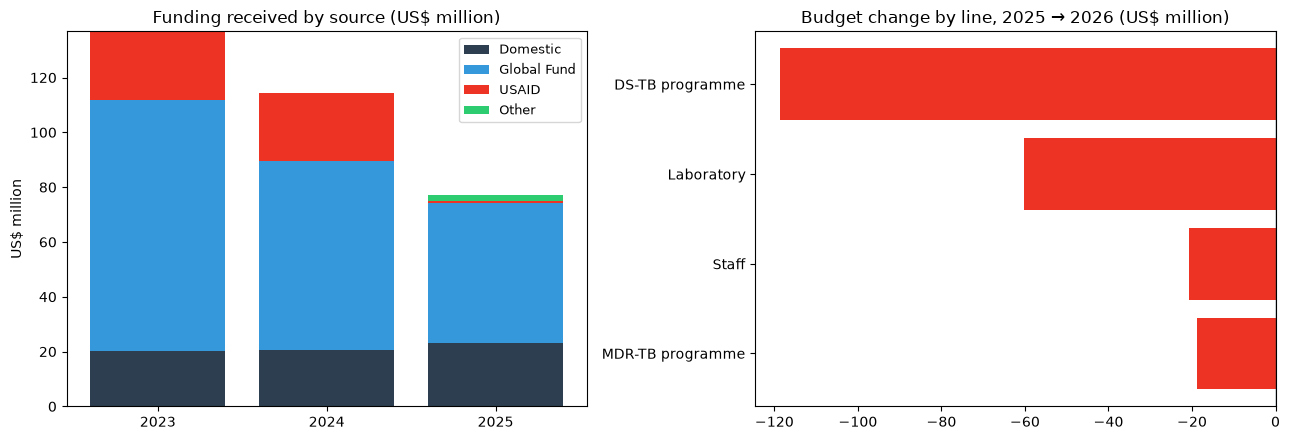

In [33]:
f = nga(fund).set_index("year").loc[[2023, 2024, 2025]]
src = {"rcvd_tot_domestic": "Domestic", "rcvd_tot_gf": "Global Fund",
       "rcvd_tot_usaid": "USAID", "rcvd_tot_grnt": "Other"}
colors = ["#2C3E50", "#3498DB", "#ED3324", "#2ECC71"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
bottom = np.zeros(len(f))
for (col, label), c in zip(src.items(), colors):
    vals = f[col].values / 1e6
    axes[0].bar(f.index.astype(str), vals, bottom=bottom, label=label, color=c)
    bottom += vals
axes[0].set_title("Funding received by source (US$ million)")
axes[0].set_ylabel("US$ million"); axes[0].legend(fontsize=9)

labels = {"budget_lab": "Laboratory", "budget_staff": "Staff",
          "budget_prog": "DS-TB programme", "budget_mdrmgt": "MDR-TB programme"}
b = nga(bud).set_index("year")
diff = ((b.loc[2026, list(labels)] - b.loc[2025, list(labels)]) / 1e6).sort_values(ascending=False)
axes[1].barh([labels[c] for c in diff.index], diff.values, color="#ED3324")
axes[1].axvline(0, color="#2C3E50", lw=1)
axes[1].set_title("Budget change by line, 2025 → 2026 (US$ million)")
plt.tight_layout(); plt.show()

**The story in three sentences:**

1. In 2025, USAID funding to Nigeria's TB programme collapsed by **97%** and total funding received fell by a third, the Global Fund is now the dominant funder (Q4, Q5).
2. The 2026 plan responded by **halving** the national TB budget, with the core drug-susceptible TB programme line cut by **87%** (Q6, Q7).
3. Yet notifications kept rising to a record **455,258** and treatment coverage reached **88%** (Q2, and the glance table). While testing volume fell **17%** (Q8). The system is running hotter on less fuel.

**Analyst's humility:** these data show *what* happened, side by side they don't prove *why*. Funding cuts and falling test volumes are consistent with each other, but proving causation needs more evidence. Good analysts narrate the pattern and flag the open questions. That's what you just did.

---
## Bonus challenges no scaffolding now

Same patterns, new questions. Columns are pointed out; the thinking is yours. Answers (with working) are at the end of the [solutions notebook](TB_starter_solutions.ipynb).

| # | Challenge | Where to look |
|---|-----------|---------------|
| B1 | In which year did treatment coverage (`c_cdr`) first reach **50% or more**? | `nga_est`, filter + `.min()` on years |
| B2 | How did **under-5 household contacts started on preventive treatment** change, 2024 → 2025? | `TB_contact_tpt…`, column `newinc_con04_prevtx` |
| B3 | Since 2015, in which year did notifications grow **fastest in % terms**? | `noti`, `c_newinc`, `.pct_change()` + `idxmax()` |
| B4 | Which **age–sex group** had the most notified cases in 2025? | `noti`, columns like `newrel_m3544` (m/f + age band), `idxmax()` |
| B5 | For 2025, how much **less was received than the budget said was needed**? | `fund.rcvd_tot` vs `bud.budget_tot` — cross-file subtraction |

In [34]:
# B2's file, ready for you:
tpt = pd.read_csv("data/TB_contact_tpt_2026-08-25.csv")
nga(tpt)[["year", "newinc_con04_prevtx"]].tail(3)

,year,newinc_con04_prevtx
1537,2023,83955.0
1538,2024,95632.0
1539,2025,29809.0


---
## 📝 Your answer checklist

Fill this in as you go (double-click this cell to edit it). Then compare with the [answer key](TB_starter_solutions.ipynb).

| # | Your answer |
|---|-------------|
| 1 | |
| 2 | |
| 3 | |
| 4 | |
| 5 | |
| 6 | |
| 7 | |
| 8 | |
| 9 | |
| 10 | |

---
## 🎓 What you just learned

| Skill | Where you used it |
|-------|-------------------|
| Downloading open data with `wget` + raw GitHub URLs | Step 1 |
| Reading a data dictionary; decoding column prefixes | Step 2, Q7, Q8 |
| Filtering with boolean masks (`&`, comparisons) | everywhere |
| `nunique` vs `count` | Q1 |
| Sorting, ranking, zero-based indexes | Q2 |
| Shares: part ÷ whole | Q3 |
| Percentage change and its base-year trap | Q4, Q6, Q8 |
| `idxmax` / `idxmin` vs `max` / `min` | Q5, Q7, Q9 |
| Missing data: NaN ≠ 0; adapt the question honestly | Q9 |
| Data-quality detective work | Q10 |

That is a genuine first course in data analysis, with a real error you found yourself.

## ⭐ Like this? Help the next learner find it

1. **Star the repo** → [github.com/thegoodworks/dataworks-tb](https://github.com/thegoodworks/dataworks-tb): stars are how other beginners discover free lessons like this.
2. **Follow [@thegoodworks](https://github.com/thegoodworks)** → Vol. 02 is coming, and your follow tells us what to build.
3. **Share your checklist**: post your answers or your own question as an [issue](https://github.com/thegoodworks/dataworks-tb/issues), or tag us. Teaching someone else is the fastest way to cement what you learned.
4. **Make it yours**: swap `"Nigeria"` for your own country in the `nga()` helper and re-run everything. Same code, new story. 

## Data attribution & licence

> Data: **World Health Organization**, *WHO Global Tuberculosis Report 2026* database (`gtb_database`, snapshot 2026-08-25), accessed 17 November 2026 via [GTB-TME/gtbreport2026](https://github.com/GTB-TME/gtbreport2026). We acknowledge the **national TB programmes and other national authorities** that provided the underlying data. Used under the [WHO data policy](https://www.who.int/about/policies/publishing/data-policy) and its [terms and conditions](https://www.who.int/about/policies/publishing/data-policy/terms-and-conditions) for public-health purposes.
>
> Notebook & code: MIT © [thegoodworks.ng](https://www.thegoodworks.ng) (**dataworks**). This is an independent educational project, **not affiliated with or endorsed by WHO**.